# Practical Assignment 6: Clustering Algorithms

**Dataset:** Handwritten Digits dataset (scikit-learn)  
**Algorithms:** K-Means, Agglomerative Clustering, DBSCAN and Gaussian Mixture Model (GMM)

**Course:** Artificial Intelligence and Machine Learning (AIML)

**Practical:** 4       
**Student Name:** Samarth Kadam         
**Roll Number:** 33           
**PRN:** 202401040131        
**Div:** A

## Aim
To apply unsupervised clustering algorithms to handwritten digit samples, discover groups with similar pixel patterns, and evaluate the quality and limitations of the resulting clusters.

## Learning objectives
1. Understand the difference between supervised classification and unsupervised clustering.
2. Explore and preprocess a real handwritten-digit sample dataset.
3. Implement four clustering algorithms with justified model-selection procedures.
4. Evaluate cluster quality using internal and external metrics.
5. Compare visualizations, cluster sizes, noise handling and algorithm limitations.

## Dataset note
The scikit-learn **Digits** dataset contains 1,797 real handwritten-digit samples represented as 8 × 8 grayscale images (64 pixel features), covering digits 0–9. It is a compact benchmark dataset containing real handwritten samples and is suitable for an educational clustering experiment. It is not a newly collected or continuously updated commercial dataset. Dataset documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html.

**Important experimental rule:** the known digit labels are held aside. They are never passed to the clustering algorithms; they are used only after fitting for external evaluation and interpretation.

## 1. Import libraries and set reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score
)
from scipy.cluster.hierarchy import linkage, dendrogram
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load and explore the dataset

Each image is 8 × 8 pixels. Flattening the image gives 64 numeric features. Pixel intensities are the input features used for clustering.

In [2]:
digits = load_digits()
X = digits.data.astype(float)
y_true = digits.target  # kept separate: evaluation only

print(f"Number of images: {X.shape[0]}")
print(f"Number of pixel features per image: {X.shape[1]}")
print(f"Image dimensions: {digits.images.shape[1]} × {digits.images.shape[2]}")
print(f"Known digit classes (evaluation only): {np.unique(y_true)}")
print(f"Missing values: {np.isnan(X).sum()}")
display(pd.DataFrame(X).describe().round(2))

Number of images: 1797
Number of pixel features per image: 64
Image dimensions: 8 × 8
Known digit classes (evaluation only): [0 1 2 3 4 5 6 7 8 9]
Missing values: 0


,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
count,1797.0,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,...,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00,1797.00
mean,0.0,0.30,5.20,11.84,11.85,5.78,1.36,0.13,0.01,1.99,...,3.73,0.21,0.00,0.28,5.56,12.09,11.81,6.76,2.07,0.36
std,0.0,0.91,4.75,4.25,4.29,5.67,3.33,1.04,0.09,3.20,...,4.92,0.98,0.02,0.93,5.10,4.37,4.93,5.90,4.09,1.86
min,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.0,0.00,1.00,10.00,10.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,11.00,10.00,0.00,0.00,0.00
50%,0.0,0.00,4.00,13.00,13.00,4.00,0.00,0.00,0.00,0.00,...,1.00,0.00,0.00,0.00,4.00,13.00,14.00,6.00,0.00,0.00
75%,0.0,0.00,9.00,15.00,15.00,11.00,0.00,0.00,0.00,3.00,...,7.00,0.00,0.00,0.00,10.00,16.00,16.00,12.00,2.00,0.00
max,0.0,8.00,16.00,16.00,16.00,16.00,16.00,15.00,2.00,16.00,...,16.00,13.00,1.00,9.00,16.00,16.00,16.00,16.00,16.00,16.00


### 2.1 Visual inspection of sample images

Visual inspection confirms that the observations are handwritten images rather than abstract numeric records.

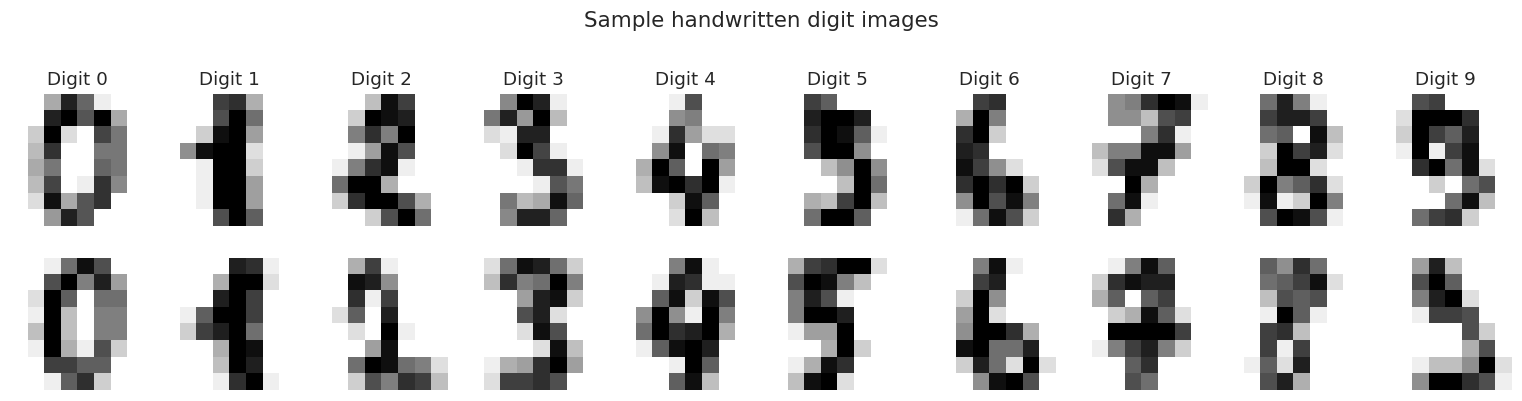

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(14, 4))
for digit_value in range(10):
    indices = np.where(y_true == digit_value)[0][:2]
    for row, idx in enumerate(indices):
        axes[row, digit_value].imshow(digits.images[idx], cmap="gray_r")
        axes[row, digit_value].axis("off")
        if row == 0:
            axes[row, digit_value].set_title(f"Digit {digit_value}")
axes[0, 0].set_ylabel("Example 1")
axes[1, 0].set_ylabel("Example 2")
fig.suptitle("Sample handwritten digit images", fontsize=14)
plt.tight_layout()
plt.show()

### 2.2 Class distribution (descriptive only)

The known digit values are shown to understand dataset balance. They are not used as clustering inputs.

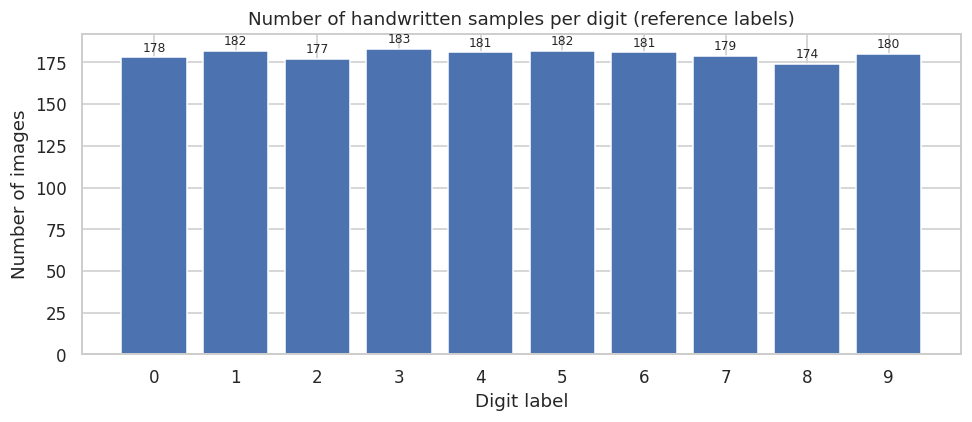

,Images
0,178
1,182
2,177
3,183
4,181
5,182
6,181
7,179
8,174
9,180


In [4]:
class_counts = pd.Series(y_true).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(class_counts.index.astype(str), class_counts.values)
ax.bar_label(bars, padding=2, fontsize=8)
ax.set(title="Number of handwritten samples per digit (reference labels)",
       xlabel="Digit label", ylabel="Number of images")
plt.tight_layout()
plt.show()
display(class_counts.rename("Images").to_frame())

## 3. Preprocessing and visualization space

Standardization is applied because distance-based methods can be affected by feature scales. PCA is used in two ways:
- **2 components:** visualization only.
- **20 components:** DBSCAN input to reduce the difficulty of density estimation in 64 dimensions.

All other algorithms use the standardized 64-dimensional pixel features. Internal evaluation scores are calculated in the same standardized 64-dimensional feature space for a consistent partition comparison. The DBSCAN labels are evaluated on the same original feature space after they have been generated in PCA space.

t-SNE is used only for visualization; it is not used to fit any clustering algorithm.

Standardized feature matrix: (1797, 64)
PCA-2 variance explained: 0.216
PCA-20 variance explained: 0.793


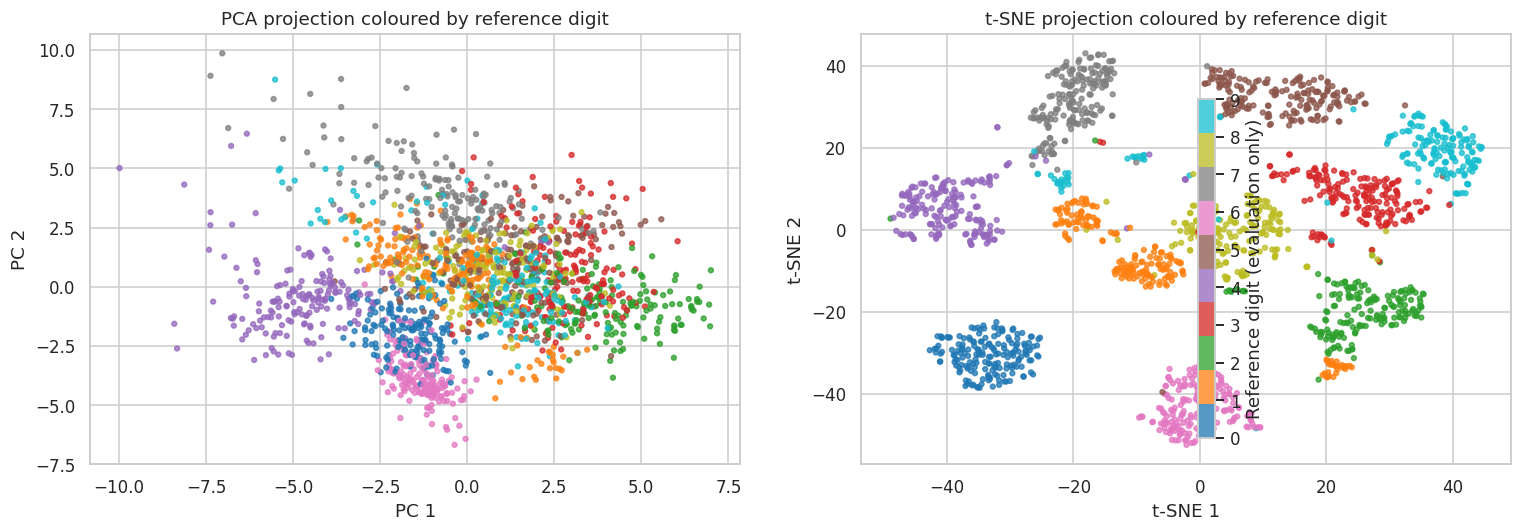

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca_2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca2 = pca_2.fit_transform(X_scaled)

pca_db = PCA(n_components=20, random_state=RANDOM_STATE)
X_pca20 = pca_db.fit_transform(X_scaled)

tsne = TSNE(n_components=2, perplexity=30, init="pca",
            learning_rate="auto", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)

print("Standardized feature matrix:", X_scaled.shape)
print("PCA-2 variance explained:", round(pca_2.explained_variance_ratio_.sum(), 3))
print("PCA-20 variance explained:", round(pca_db.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc = axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=y_true,
                     cmap="tab10", s=10, alpha=.75)
axes[0].set_title("PCA projection coloured by reference digit")
axes[0].set_xlabel("PC 1"); axes[0].set_ylabel("PC 2")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_true,
                cmap="tab10", s=10, alpha=.75)
axes[1].set_title("t-SNE projection coloured by reference digit")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")
fig.colorbar(sc, ax=axes, label="Reference digit (evaluation only)", shrink=.8)
plt.tight_layout()
plt.show()

## 4. Evaluation metrics and fair comparison

| Metric | Type | Preferred direction | Interpretation |
|---|---|---|---|
| Silhouette Score | Internal | Higher; range −1 to +1 | Cohesion within clusters versus separation from other clusters. |
| Davies–Bouldin Index | Internal | Lower | Average similarity between each cluster and its most similar competing cluster. |
| Calinski–Harabasz Index | Internal | Higher | Ratio of between-cluster dispersion to within-cluster dispersion. |
| Adjusted Rand Index (ARI) | External | Higher; maximum 1 | Agreement between cluster assignments and known digit labels, adjusted for chance. |
| Normalized Mutual Information (NMI) | External | Higher; maximum 1 | Shared information between clusters and known digit labels. |

**Noise handling:** DBSCAN assigns some observations the label `-1` (noise). Internal metrics are computed only on non-noise observations, and the retained-data coverage is reported separately. ARI and NMI are calculated on all observations, including noise, so rejected observations are not silently removed from external evaluation.

A high internal score does not necessarily mean clusters correspond to the ten digit identities. Internal and external metrics answer different questions.

In [6]:
def evaluate_clustering(X_eval, labels, reference_labels=y_true):
    labels = np.asarray(labels)
    noise_mask = labels == -1
    valid_mask = ~noise_mask
    valid_labels = labels[valid_mask]
    unique_clusters = np.unique(valid_labels)
    n_clusters = len(unique_clusters)
    n_valid = int(valid_mask.sum())
    coverage = n_valid / len(labels)

    result = {
        "Clusters": n_clusters,
        "Noise points": int(noise_mask.sum()),
        "Coverage (%)": 100 * coverage,
        "Silhouette": np.nan,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan,
        "ARI": adjusted_rand_score(reference_labels, labels),
        "NMI": normalized_mutual_info_score(reference_labels, labels)
    }

    # Internal metrics need at least 2 clusters and more observations than clusters.
    if n_clusters >= 2 and n_valid > n_clusters:
        X_valid = X_eval[valid_mask]
        result["Silhouette"] = silhouette_score(X_valid, valid_labels)
        result["Davies-Bouldin"] = davies_bouldin_score(X_valid, valid_labels)
        result["Calinski-Harabasz"] = calinski_harabasz_score(X_valid, valid_labels)
    return result

print("Metric function ready.")

Metric function ready.


## 4.1 Why these four algorithms were selected

The four methods provide contrasting clustering assumptions, which makes them useful for a comparative experiment:

| Algorithm | Main assumption / strength | Why it is included |
|---|---|---|
| K-Means | Compact groups represented by centroids | Provides a simple, computationally efficient baseline. |
| Agglomerative | Similar observations can be merged hierarchically | Provides a dendrogram and reveals nested grouping structure. |
| DBSCAN | Clusters are dense regions separated by sparse regions | Can discover irregular groups and identify noise without preselecting cluster count. |
| GMM | Data can be represented by a mixture of probability distributions | Supports overlapping groups and probabilistic membership. |

The methods are not expected to produce identical labels. Their different assumptions are precisely what the comparison is intended to examine.

## 5. K-Means clustering

K-Means assigns each sample to its nearest centroid and updates centroids to reduce within-cluster squared distances.

**Model selection:** test candidate values of `k` from 2 to 12. Use both the Elbow curve (inertia) and Silhouette Score. The selected `k` is the candidate with the highest silhouette score in this declared search range; the Elbow curve is shown as a complementary diagnostic rather than treated as an exact automatic rule.

,Inertia,Silhouette
k,,
2,100423.8430,0.1056
3,93836.3854,0.1054
4,89120.9887,0.0954
5,85096.0547,0.1023
6,81678.4667,0.0988
7,77671.3389,0.1220
8,74854.1592,0.1266
9,72025.6149,0.1307
10,69486.5145,0.1423


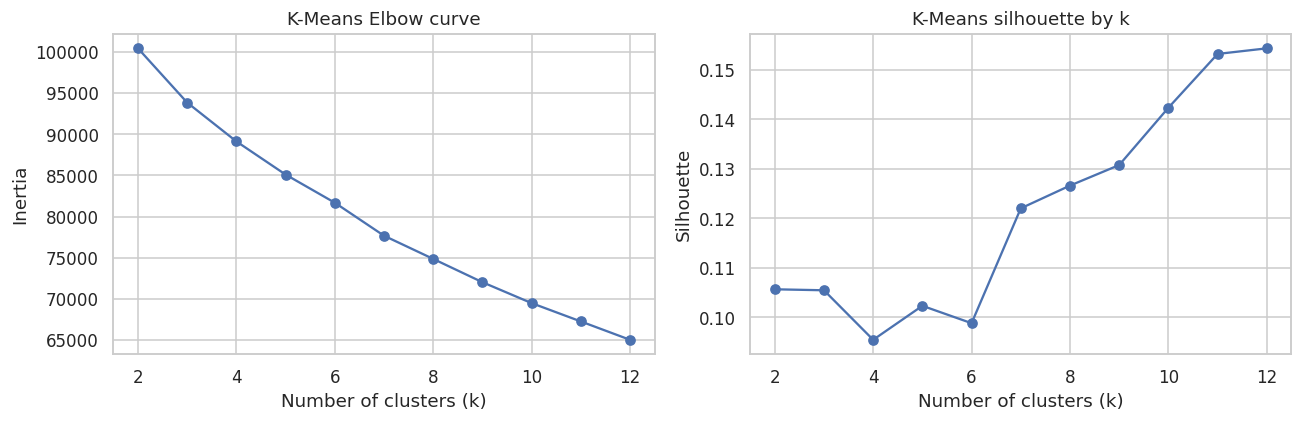

Selected K-Means cluster count: 12


In [7]:
K_RANGE = range(2, 13)
k_rows = []

for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels_k = model.fit_predict(X_scaled)
    k_rows.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels_k)
    })

k_results = pd.DataFrame(k_rows).set_index("k")
display(k_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_results.index, k_results["Inertia"], marker="o")
axes[0].set(title="K-Means Elbow curve", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(k_results.index, k_results["Silhouette"], marker="o")
axes[1].set(title="K-Means silhouette by k", xlabel="Number of clusters (k)", ylabel="Silhouette")
plt.tight_layout()
plt.show()

BEST_K = int(k_results["Silhouette"].idxmax())
print(f"Selected K-Means cluster count: {BEST_K}")

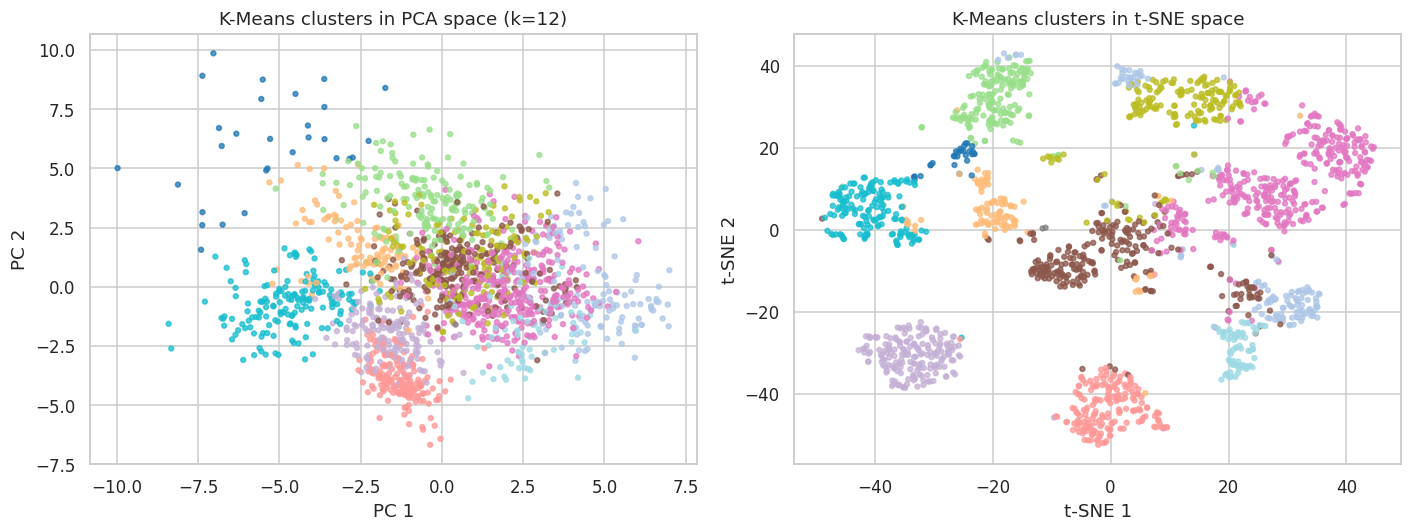

,Clusters,Noise points,Coverage (%),Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
K-Means,12,0,100.0,0.1543,1.7207,111.253,0.5512,0.6788


In [8]:
kmeans = KMeans(n_clusters=BEST_K, n_init=30, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=kmeans_labels,
                cmap="tab20", s=10, alpha=.75)
axes[0].set(title=f"K-Means clusters in PCA space (k={BEST_K})",
            xlabel="PC 1", ylabel="PC 2")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels,
                cmap="tab20", s=10, alpha=.75)
axes[1].set(title="K-Means clusters in t-SNE space",
            xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout()
plt.show()

display(pd.DataFrame([evaluate_clustering(X_scaled, kmeans_labels)],
                     index=["K-Means"]).round(4))

## 6. Agglomerative (Hierarchical) clustering

Agglomerative clustering starts with each observation as an individual cluster and repeatedly merges the closest groups. Ward linkage merges clusters to minimize the increase in within-cluster variance.

The dendrogram is constructed from a reproducible sample of 400 observations so it remains readable. The final model is fitted to the full dataset using the same selected cluster count as K-Means, which makes the comparison easier to interpret.

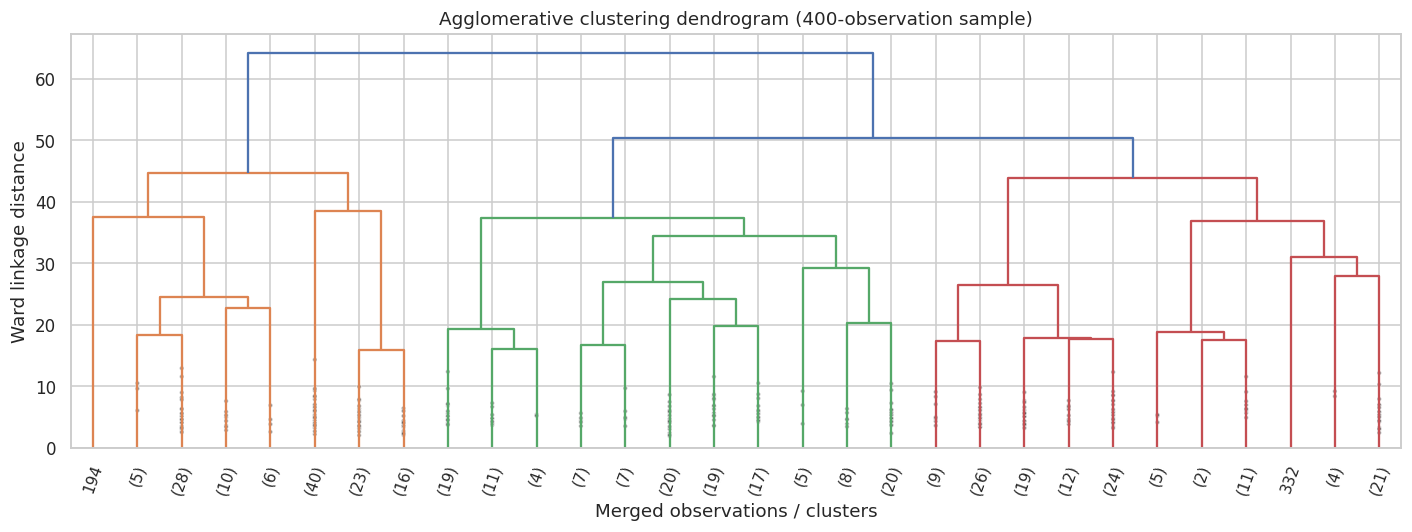

In [9]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_scaled), size=400, replace=False)
Z = linkage(X_scaled[sample_idx], method="ward")

plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=30,
           leaf_rotation=70, show_contracted=True)
plt.title("Agglomerative clustering dendrogram (400-observation sample)")
plt.xlabel("Merged observations / clusters")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

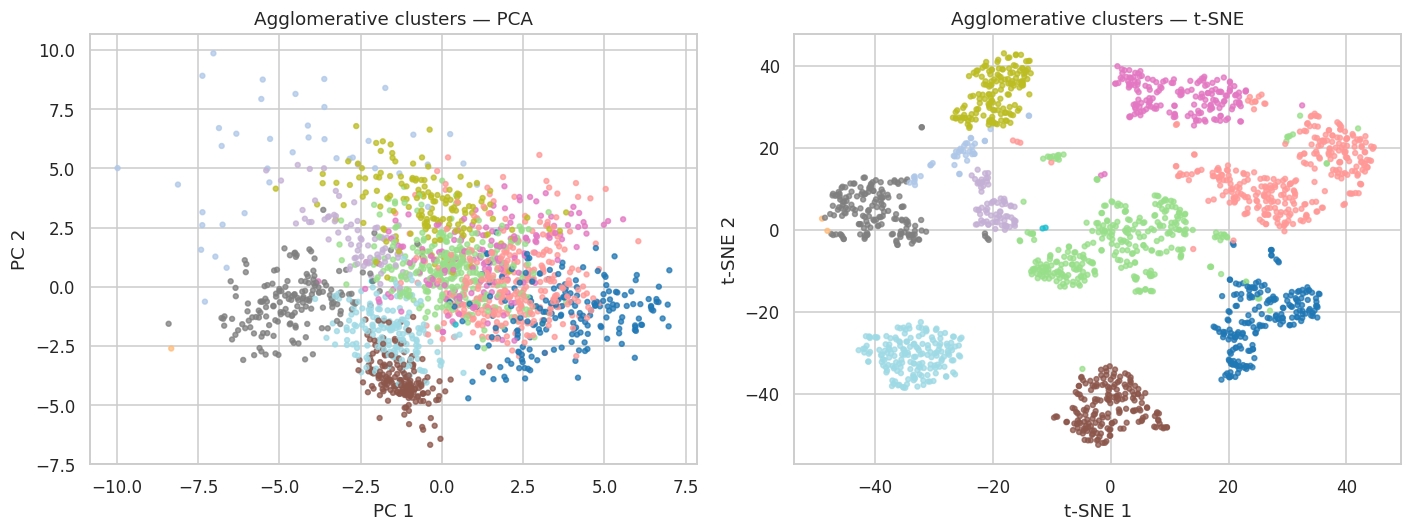

,Clusters,Noise points,Coverage (%),Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
Agglomerative,12,0,100.0,0.1344,1.8064,104.1757,0.6825,0.793


In [10]:
agglo = AgglomerativeClustering(n_clusters=BEST_K, linkage="ward")
agglo_labels = agglo.fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=agglo_labels,
                cmap="tab20", s=10, alpha=.75)
axes[0].set(title="Agglomerative clusters — PCA", xlabel="PC 1", ylabel="PC 2")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=agglo_labels,
                cmap="tab20", s=10, alpha=.75)
axes[1].set(title="Agglomerative clusters — t-SNE",
            xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout()
plt.show()

display(pd.DataFrame([evaluate_clustering(X_scaled, agglo_labels)],
                     index=["Agglomerative"]).round(4))

## 7. DBSCAN (Density-Based Spatial Clustering)

DBSCAN groups observations in dense regions and labels isolated observations as noise (`-1`). It does not require a preselected number of clusters.

**High-dimensionality consideration:** density estimation becomes difficult in 64 dimensions. For this experiment DBSCAN is fitted on the first 20 standardized-data PCA components. The number of retained components and explained variance are reported above. The final labels are still evaluated in the common 64-dimensional standardized feature space.

**Parameter selection:** use a k-distance diagnostic and a transparent grid over `min_samples` and quantiles of the k-nearest-neighbour distance. Candidate settings must produce at least two clusters, each with at least 10 observations, and retain at least 20% of the observations. Among eligible candidates, select the highest `Silhouette × coverage` score. This rewards separation while discouraging settings that reject most of the dataset. It does not guarantee semantically meaningful digit groups.

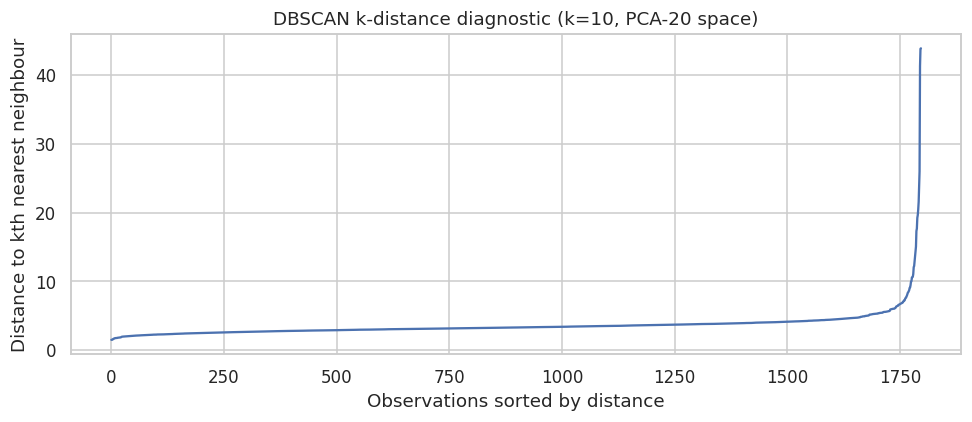

In [11]:
MIN_SAMPLES_CANDIDATES = [5, 8, 10, 12, 15]
EPS_QUANTILES = [0.75, 0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99]

# k-distance plot for a representative min_samples value
diagnostic_k = 10
knn_distances, _ = NearestNeighbors(n_neighbors=diagnostic_k).fit(X_pca20).kneighbors(X_pca20)
sorted_kdist = np.sort(knn_distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(sorted_kdist)
plt.title(f"DBSCAN k-distance diagnostic (k={diagnostic_k}, PCA-20 space)")
plt.xlabel("Observations sorted by distance")
plt.ylabel("Distance to kth nearest neighbour")
plt.tight_layout()
plt.show()

In [12]:
dbscan_rows = []
for min_samples in MIN_SAMPLES_CANDIDATES:
    distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(X_pca20).kneighbors(X_pca20)
    kth_distances = distances[:, -1]
    for q in EPS_QUANTILES:
        eps = float(np.quantile(kth_distances, q))
        labels_try = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_pca20)
        result = evaluate_clustering(X_scaled, labels_try)
        non_noise_labels = labels_try[labels_try != -1]
        cluster_sizes = pd.Series(non_noise_labels).value_counts()
        min_cluster_size = int(cluster_sizes.min()) if len(cluster_sizes) else 0
        max_cluster_share = float(cluster_sizes.max() / len(labels_try)) if len(cluster_sizes) else 1.0
        eligible = (
            result["Clusters"] >= 2 and
            min_cluster_size >= 10 and
            result["Coverage (%)"] >= 20
        )
        objective = (
            result["Silhouette"] * result["Coverage (%)"] / 100
            if eligible and pd.notna(result["Silhouette"]) else np.nan
        )
        dbscan_rows.append({
            "eps": eps, "min_samples": min_samples, "quantile": q,
            **result, "Smallest cluster": min_cluster_size,
            "Largest cluster share (%)": 100 * max_cluster_share,
            "Eligible": eligible, "Selection score": objective
        })

dbscan_search = pd.DataFrame(dbscan_rows)
display(dbscan_search.sort_values("Selection score", ascending=False, na_position="last").head(12).round(4))

,eps,min_samples,quantile,Clusters,Noise points,Coverage (%),Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI,Smallest cluster,Largest cluster share (%),Eligible,Selection score
10,3.8010,8,0.80,2,138,92.3205,0.2615,1.2259,53.7282,0.0016,0.0408,27,90.8180,True,0.2414
18,3.8158,10,0.75,2,149,91.7084,0.2625,1.2245,53.9807,0.0016,0.0405,27,90.2059,True,0.2408
36,4.1449,15,0.75,2,134,92.5431,0.2592,1.1938,46.6651,0.0013,0.0364,23,91.2632,True,0.2399
19,3.9887,10,0.80,2,121,93.2666,0.2557,1.2577,53.6412,0.0016,0.0422,28,91.7084,True,0.2385
27,3.9759,12,0.75,2,133,92.5988,0.2515,1.2583,51.0369,0.0016,0.0400,27,91.0963,True,0.2329
9,3.6661,8,0.75,2,177,90.1503,0.2548,1.2186,50.8973,0.0021,0.0413,26,88.7034,True,0.2297
0,3.3165,5,0.75,4,232,87.0896,-0.0123,1.5045,19.4766,0.0036,0.0552,4,85.1419,False,NaN
1,3.4625,5,0.80,4,174,90.3172,0.0158,1.3537,21.8285,0.0019,0.0493,5,88.3139,False,NaN
2,3.6487,5,0.85,3,140,92.2092,0.2125,1.1714,31.2868,0.0015,0.0451,6,90.4285,False,NaN
3,3.9606,5,0.90,1,91,94.9360,NaN,NaN,NaN,0.0005,0.0120,1706,94.9360,False,NaN


Selected DBSCAN parameters: eps=3.8010, min_samples=8
Clusters found: 2
Noise observations: 138 / 1797
Retained coverage: 92.3%


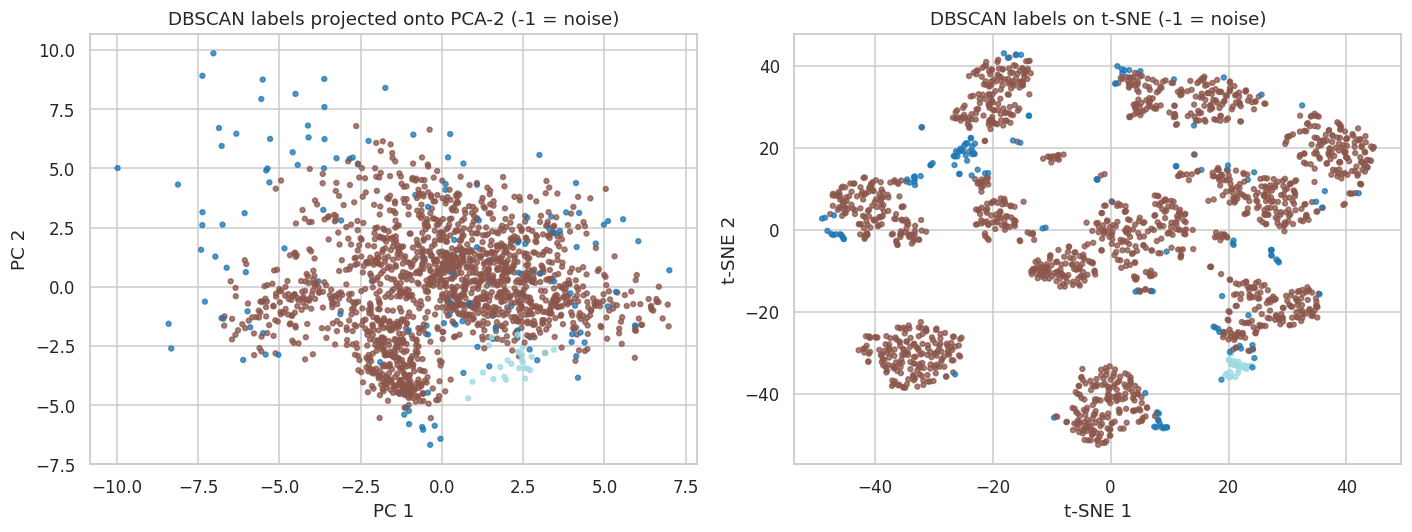

,Clusters,Noise points,Coverage (%),Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
DBSCAN,2,138,92.3205,0.2615,1.2259,53.7282,0.0016,0.0408


In [13]:
eligible_db = dbscan_search[dbscan_search["Eligible"]].dropna(subset=["Selection score"])
if eligible_db.empty:
    raise RuntimeError(
        "No DBSCAN setting met the stated minimum-cluster and coverage criteria. "
        "Report DBSCAN as unsuitable under this search rather than inventing a fallback."
    )

best_db = eligible_db.sort_values("Selection score", ascending=False).iloc[0]
EPS = float(best_db["eps"])
DB_MIN_SAMPLES = int(best_db["min_samples"])

dbscan = DBSCAN(eps=EPS, min_samples=DB_MIN_SAMPLES)
dbscan_labels = dbscan.fit_predict(X_pca20)

print(f"Selected DBSCAN parameters: eps={EPS:.4f}, min_samples={DB_MIN_SAMPLES}")
print(f"Clusters found: {len(set(dbscan_labels) - {-1})}")
print(f"Noise observations: {(dbscan_labels == -1).sum()} / {len(dbscan_labels)}")
print(f"Retained coverage: {(dbscan_labels != -1).mean()*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=dbscan_labels,
                cmap="tab20", s=10, alpha=.75)
axes[0].set(title="DBSCAN labels projected onto PCA-2 (-1 = noise)",
            xlabel="PC 1", ylabel="PC 2")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=dbscan_labels,
                cmap="tab20", s=10, alpha=.75)
axes[1].set(title="DBSCAN labels on t-SNE (-1 = noise)",
            xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout()
plt.show()

display(pd.DataFrame([evaluate_clustering(X_scaled, dbscan_labels)],
                     index=["DBSCAN"]).round(4))

## 8. Gaussian Mixture Model (GMM)

GMM represents the data as a mixture of Gaussian probability distributions. It assigns each observation to the component with the highest posterior probability and can also provide soft membership probabilities.

**Model selection:** fit candidate component counts from 2 to 12 using diagonal covariance matrices. Select the component count with the lowest Bayesian Information Criterion (BIC). BIC balances model fit with a penalty for model complexity.

,BIC
Components,
2,89866.01
3,-12073.32
4,-20419.75
5,-41648.93
6,-43919.94
7,-57710.06
8,-60205.14
9,-76890.27
10,-95540.12


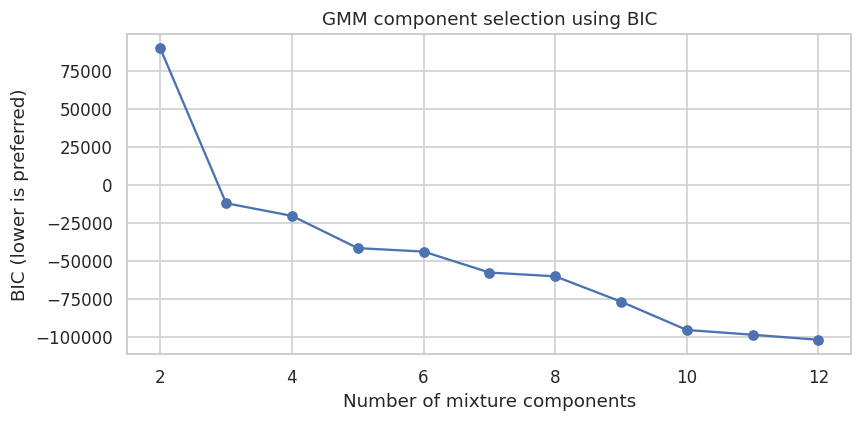

Selected GMM components: 12


In [14]:
GMM_RANGE = range(2, 13)
gmm_bic_rows = []
for k in GMM_RANGE:
    model = GaussianMixture(
        n_components=k, covariance_type="diag",
        n_init=3, reg_covar=1e-5, random_state=RANDOM_STATE
    )
    model.fit(X_scaled)
    gmm_bic_rows.append({"Components": k, "BIC": model.bic(X_scaled)})

gmm_bic_table = pd.DataFrame(gmm_bic_rows).set_index("Components")
display(gmm_bic_table.round(2))

plt.figure(figsize=(8, 4))
plt.plot(gmm_bic_table.index, gmm_bic_table["BIC"], marker="o")
plt.title("GMM component selection using BIC")
plt.xlabel("Number of mixture components")
plt.ylabel("BIC (lower is preferred)")
plt.tight_layout()
plt.show()

GMM_K = int(gmm_bic_table["BIC"].idxmin())
print(f"Selected GMM components: {GMM_K}")

Mean maximum membership probability: 0.995
Observations with confidence below 0.60: 4


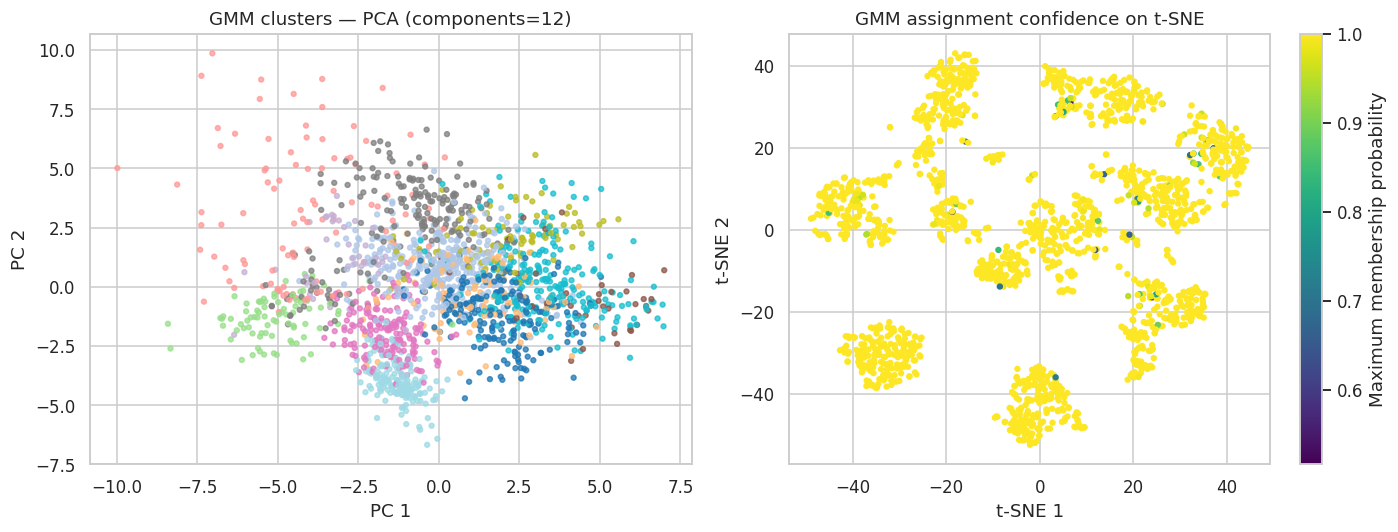

,Clusters,Noise points,Coverage (%),Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
Gaussian Mixture,12,0,100.0,0.0861,2.4844,73.3824,0.4367,0.5814


In [15]:
gmm = GaussianMixture(
    n_components=GMM_K, covariance_type="diag",
    n_init=5, reg_covar=1e-5, random_state=RANDOM_STATE
)
gmm_labels = gmm.fit_predict(X_scaled)
gmm_probabilities = gmm.predict_proba(X_scaled)
gmm_confidence = gmm_probabilities.max(axis=1)

print(f"Mean maximum membership probability: {gmm_confidence.mean():.3f}")
print(f"Observations with confidence below 0.60: {(gmm_confidence < 0.60).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=gmm_labels,
                cmap="tab20", s=10, alpha=.75)
axes[0].set(title=f"GMM clusters — PCA (components={GMM_K})",
            xlabel="PC 1", ylabel="PC 2")
sc = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1],
                     c=gmm_confidence, cmap="viridis", s=10)
axes[1].set(title="GMM assignment confidence on t-SNE",
            xlabel="t-SNE 1", ylabel="t-SNE 2")
fig.colorbar(sc, ax=axes[1], label="Maximum membership probability")
plt.tight_layout()
plt.show()

display(pd.DataFrame([evaluate_clustering(X_scaled, gmm_labels)],
                     index=["Gaussian Mixture"]).round(4))

## 9. Comparative evaluation of all algorithms

The following comparison is generated directly from the fitted models. The internal metrics use the standardized 64-feature representation for all methods. For DBSCAN, noise points are excluded from internal metrics and the retained coverage is displayed; external metrics use every observation.


In [16]:
all_methods = {
    "K-Means": kmeans_labels,
    "Agglomerative": agglo_labels,
    "DBSCAN": dbscan_labels,
    "Gaussian Mixture": gmm_labels
}

comparison = pd.DataFrame({
    name: evaluate_clustering(X_scaled, labels)
    for name, labels in all_methods.items()
}).T

display(comparison.round(4))

,Clusters,Noise points,Coverage (%),Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
K-Means,12.0,0.0,100.0000,0.1543,1.7207,111.2530,0.5512,0.6788
Agglomerative,12.0,0.0,100.0000,0.1344,1.8064,104.1757,0.6825,0.7930
DBSCAN,2.0,138.0,92.3205,0.2615,1.2259,53.7282,0.0016,0.0408
Gaussian Mixture,12.0,0.0,100.0000,0.0861,2.4844,73.3824,0.4367,0.5814


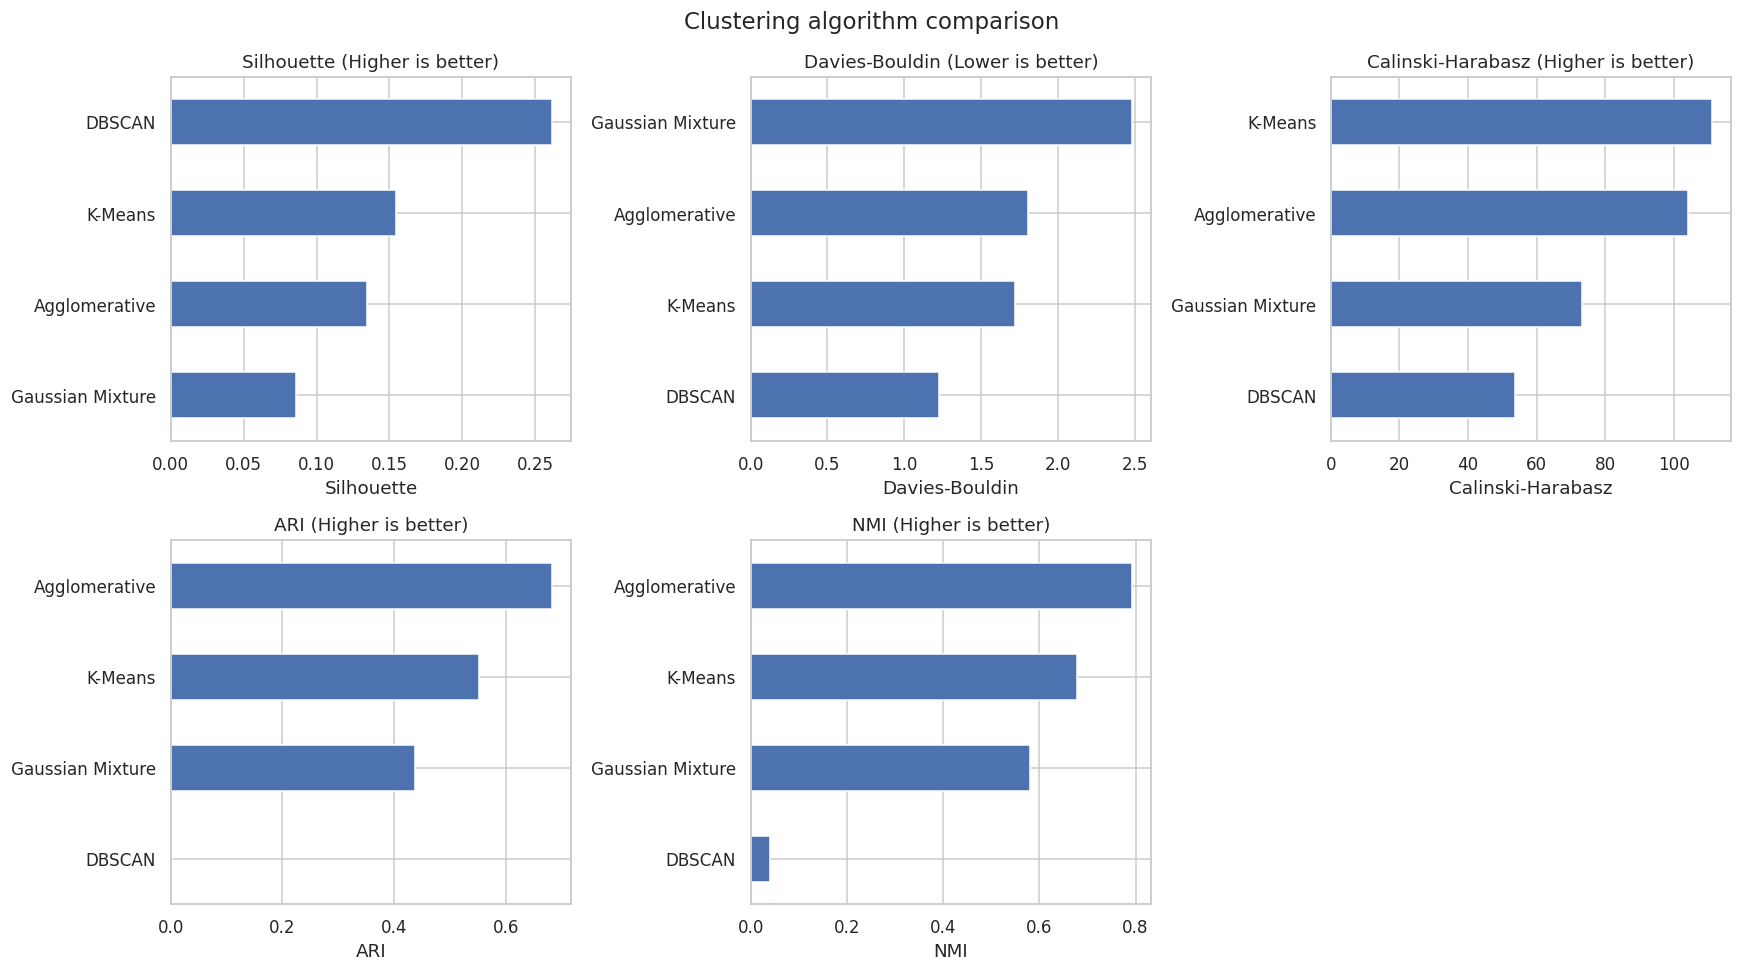

In [17]:
metric_specs = [
    ("Silhouette", "Higher is better"),
    ("Davies-Bouldin", "Lower is better"),
    ("Calinski-Harabasz", "Higher is better"),
    ("ARI", "Higher is better"),
    ("NMI", "Higher is better")
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (metric, direction) in zip(axes.ravel(), metric_specs):
    vals = comparison[metric].dropna().sort_values(ascending=True)
    vals.plot(kind="barh", ax=ax)
    ax.set_title(f"{metric} ({direction})")
    ax.set_xlabel(metric)
    ax.set_ylabel("")
axes[-1, -1].axis("off")
plt.suptitle("Clustering algorithm comparison", fontsize=15)
plt.tight_layout()
plt.show()

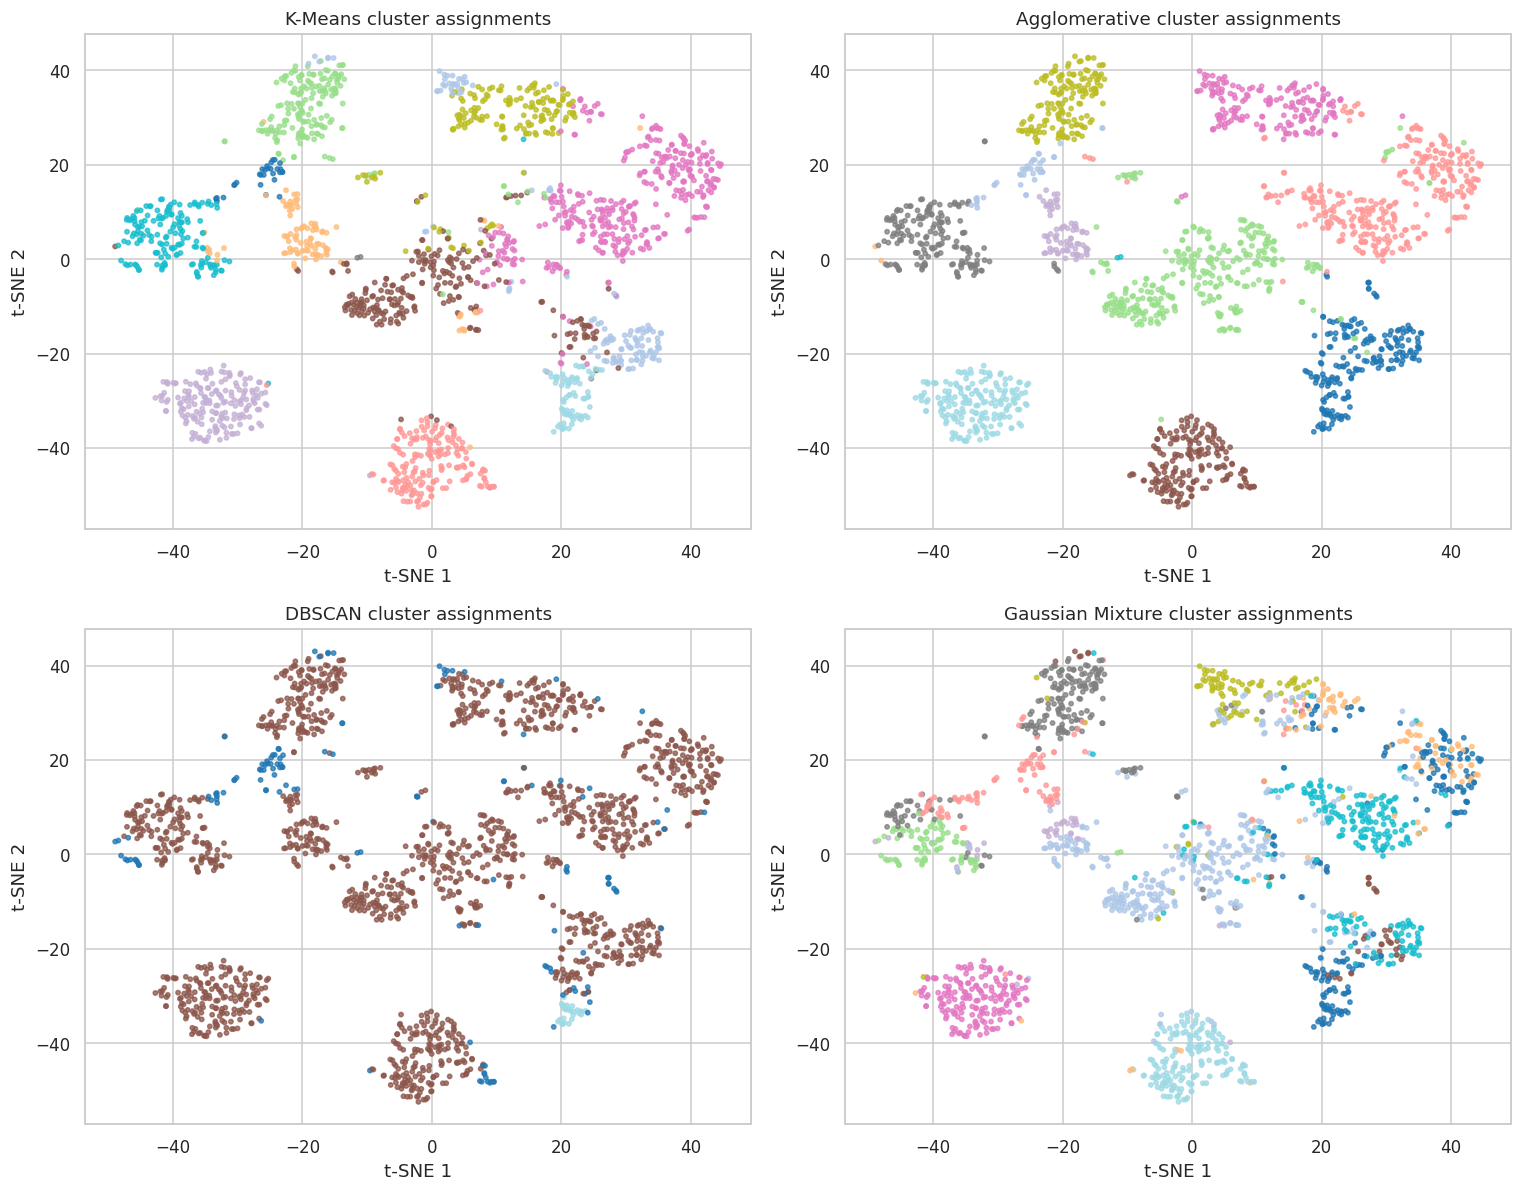

In [18]:
# One shared t-SNE coordinate system makes the cluster maps visually comparable.
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (name, labels) in zip(axes.ravel(), all_methods.items()):
    ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels,
               cmap="tab20", s=8, alpha=.75)
    ax.set_title(f"{name} cluster assignments")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

## 10. Cluster-size and cluster-composition analysis

Cluster labels are arbitrary identifiers. A cluster numbered `0` does not inherently mean digit zero. The composition heatmap uses known digit labels only after clustering to understand what each cluster contains.

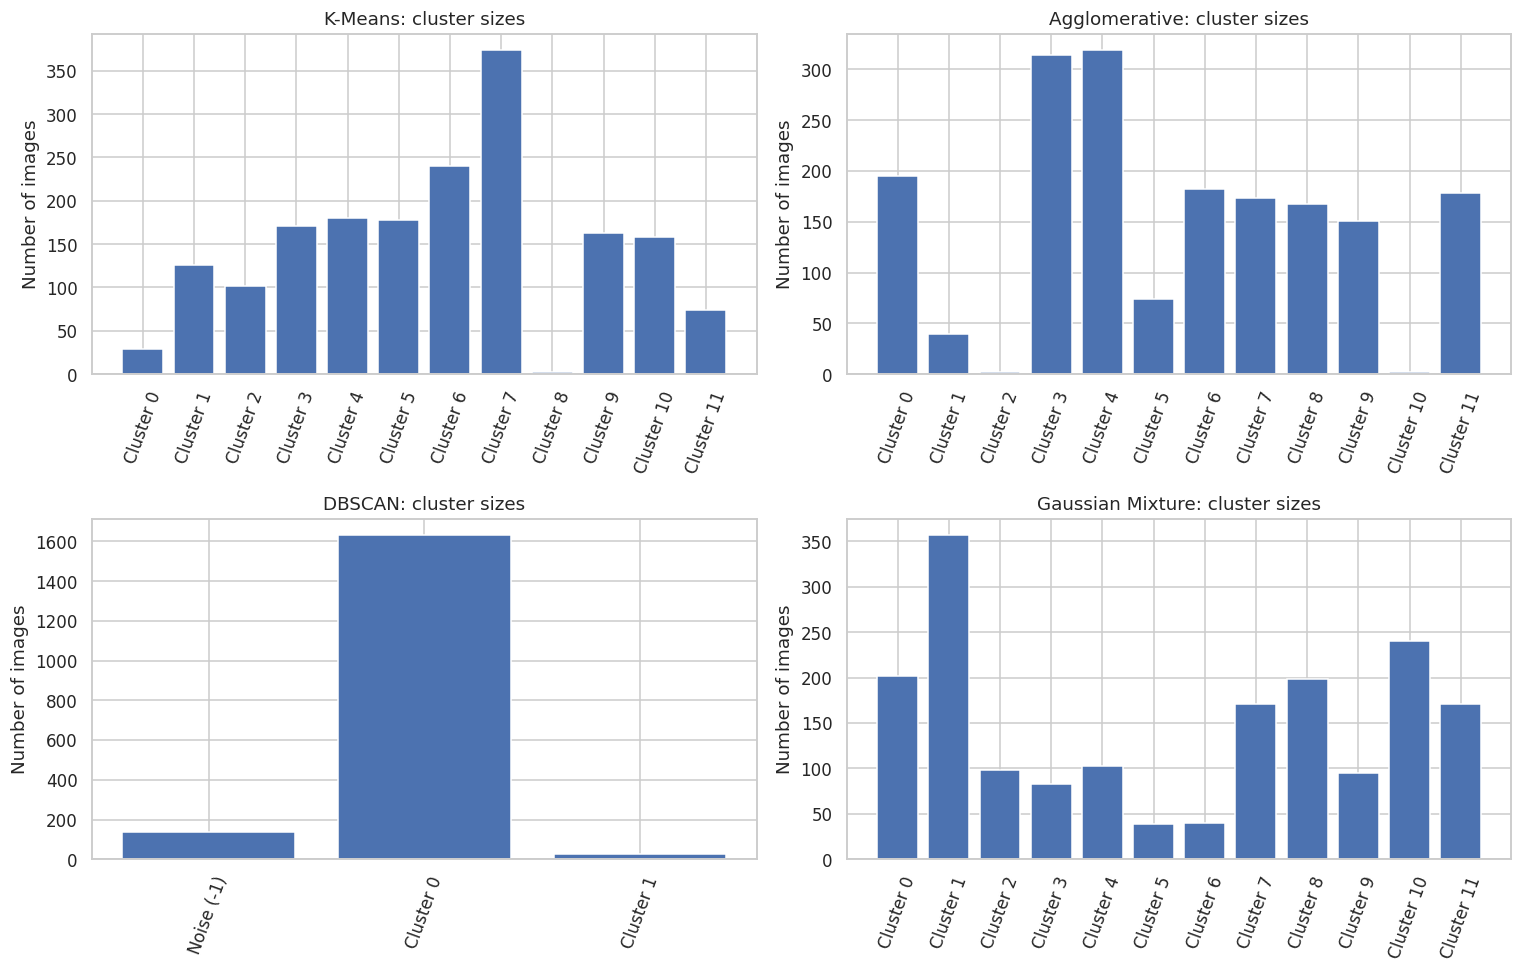

Cluster,Cluster 0,Cluster 1,Cluster 10,Cluster 11,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7,Cluster 8,Cluster 9,Noise (-1)
Algorithm,,,,,,,,,,,,,
Agglomerative,195.0,40.0,2.0,178.0,2.0,314.0,319.0,74.0,182.0,173.0,167.0,151.0,0.0
DBSCAN,1632.0,27.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,138.0
Gaussian Mixture,202.0,357.0,240.0,171.0,98.0,83.0,103.0,39.0,40.0,171.0,198.0,95.0,0.0
K-Means,29.0,126.0,158.0,74.0,102.0,171.0,180.0,178.0,240.0,374.0,2.0,163.0,0.0


In [19]:
size_rows = []
for name, labels in all_methods.items():
    labels = np.asarray(labels)
    for cluster_id in np.unique(labels):
        size_rows.append({
            "Algorithm": name,
            "Cluster": "Noise (-1)" if cluster_id == -1 else f"Cluster {cluster_id}",
            "Count": int((labels == cluster_id).sum())
        })
cluster_sizes = pd.DataFrame(size_rows)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes.ravel(), all_methods.keys()):
    subset = cluster_sizes[cluster_sizes["Algorithm"] == name]
    ax.bar(subset["Cluster"], subset["Count"])
    ax.set_title(f"{name}: cluster sizes")
    ax.set_ylabel("Number of images")
    ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

display(cluster_sizes.pivot_table(index="Algorithm", columns="Cluster",
                                  values="Count", fill_value=0))

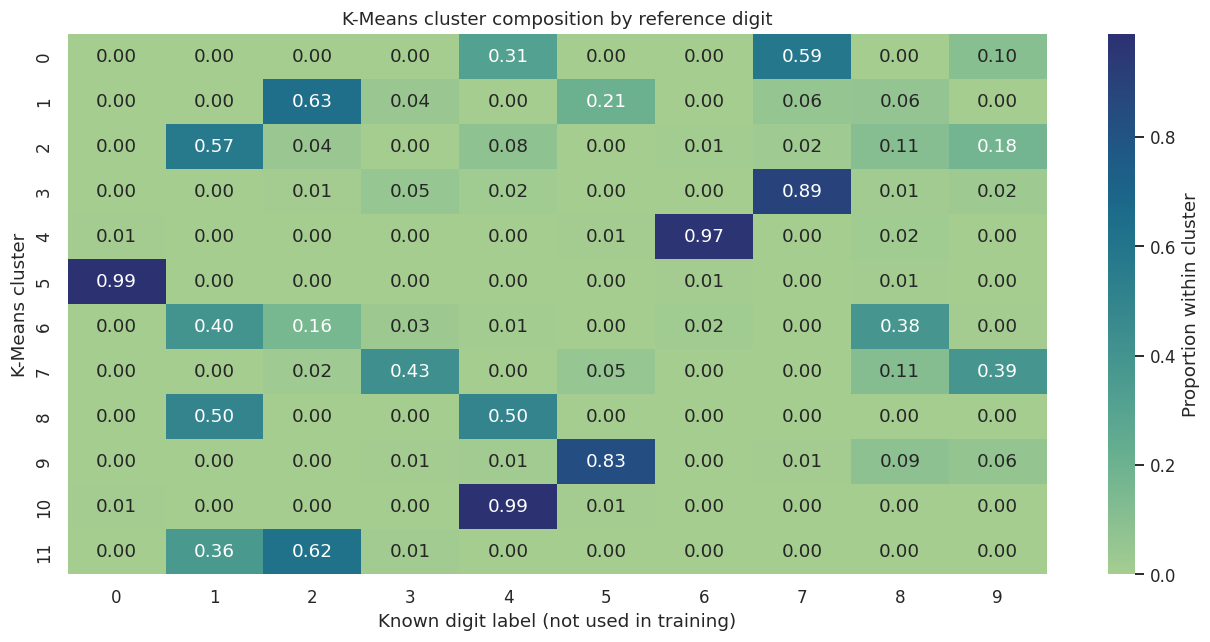

In [20]:
# K-Means cluster composition by known digit identity (evaluation only)
composition = pd.crosstab(
    pd.Series(kmeans_labels, name="K-Means cluster"),
    pd.Series(y_true, name="Known digit (evaluation only)"),
    normalize="index"
)
plt.figure(figsize=(12, 6))
sns.heatmap(composition, annot=True, fmt=".2f", cmap="crest",
            cbar_kws={"label": "Proportion within cluster"})
plt.title("K-Means cluster composition by reference digit")
plt.xlabel("Known digit label (not used in training)")
plt.ylabel("K-Means cluster")
plt.tight_layout()
plt.show()

### 10.1 Representative images and average prototypes

The examples below help interpret what visual patterns a cluster contains. An average prototype is a pixel-wise mean; it may look blurry when a cluster combines several writing styles or digit identities.

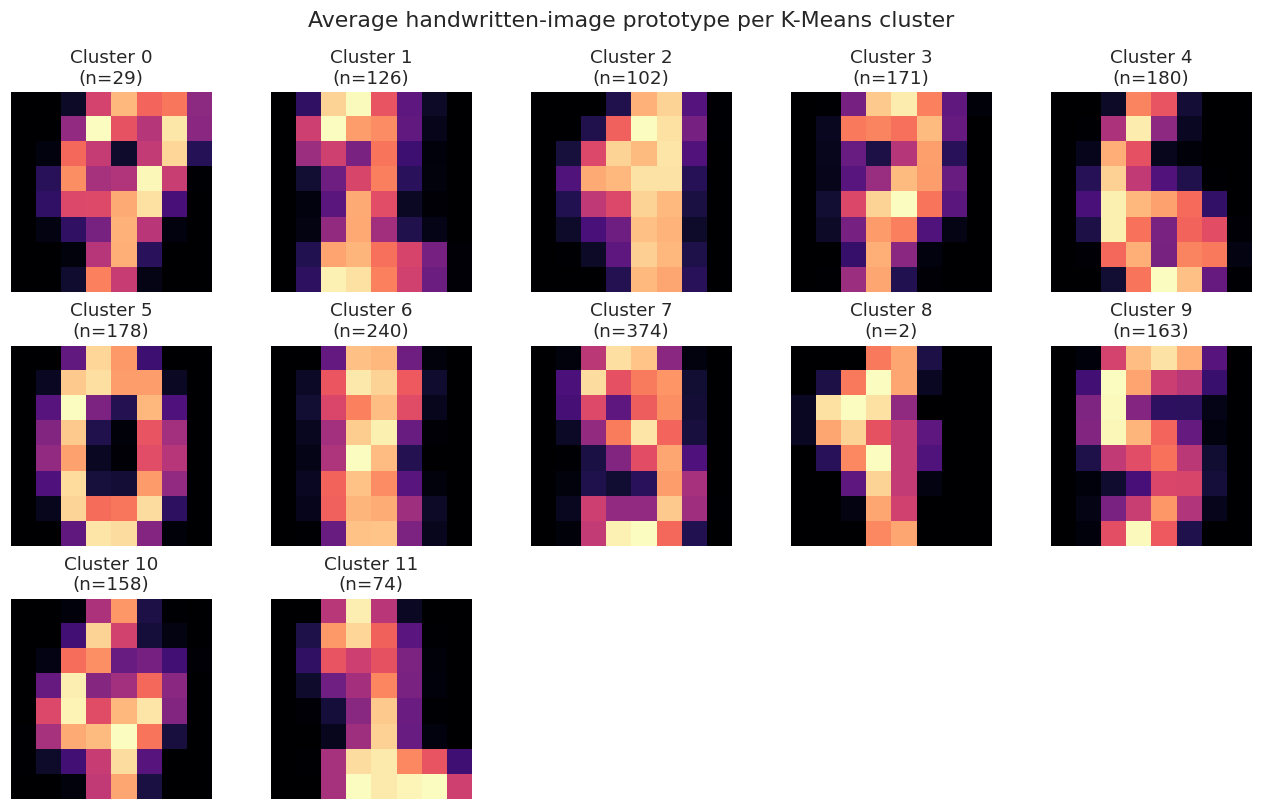

In [21]:
# Display the average image for each K-Means cluster.
ncols = 5
nrows = int(np.ceil(BEST_K / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.5*nrows))
axes = np.atleast_1d(axes).ravel()
for cluster_id in range(BEST_K):
    cluster_mean = X[kmeans_labels == cluster_id].mean(axis=0).reshape(8, 8)
    axes[cluster_id].imshow(cluster_mean, cmap="magma")
    axes[cluster_id].set_title(f"Cluster {cluster_id}\n(n={(kmeans_labels == cluster_id).sum()})")
    axes[cluster_id].axis("off")
for ax in axes[BEST_K:]:
    ax.axis("off")
fig.suptitle("Average handwritten-image prototype per K-Means cluster")
plt.tight_layout()
plt.show()

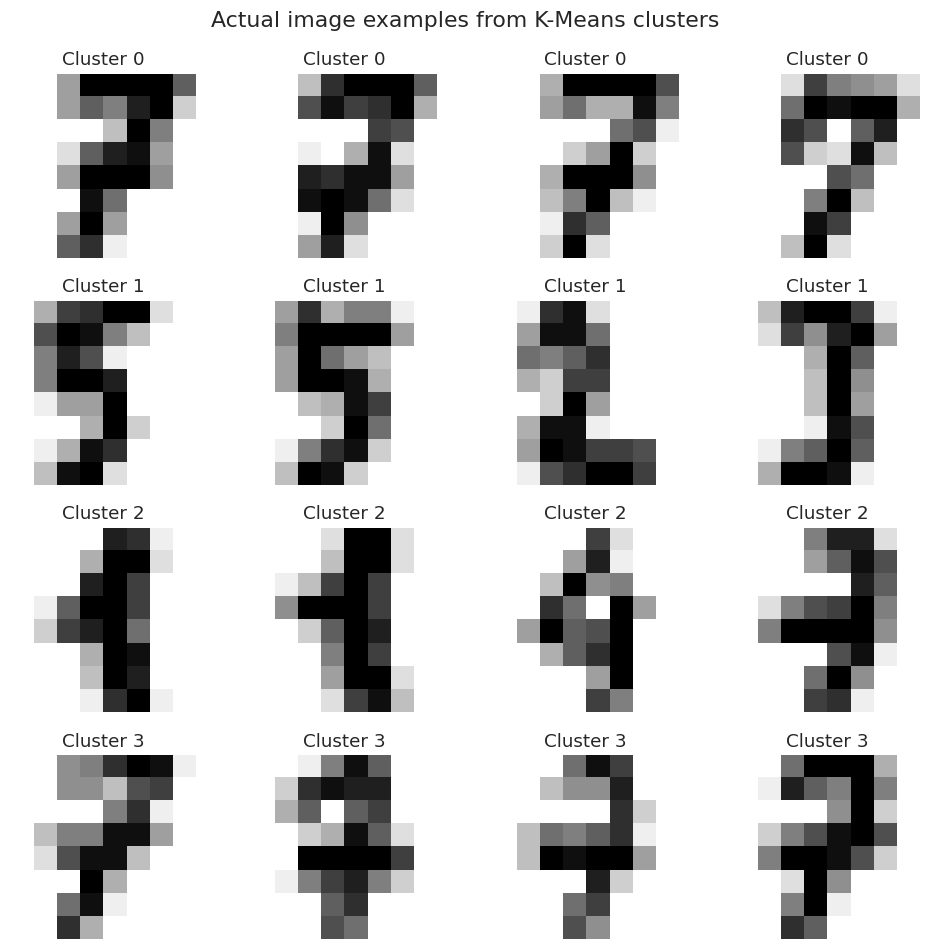

In [22]:
# Show up to four actual examples from selected K-Means clusters.
selected_clusters = np.unique(kmeans_labels)[:min(4, BEST_K)]
fig, axes = plt.subplots(len(selected_clusters), 4, figsize=(9, 2.2*len(selected_clusters)))
axes = np.atleast_2d(axes)
for row, cluster_id in enumerate(selected_clusters):
    example_ids = np.where(kmeans_labels == cluster_id)[0][:4]
    for col in range(4):
        axes[row, col].axis("off")
        if col < len(example_ids):
            idx = example_ids[col]
            axes[row, col].imshow(digits.images[idx], cmap="gray_r")
            axes[row, col].set_title(f"Cluster {cluster_id}")
plt.suptitle("Actual image examples from K-Means clusters")
plt.tight_layout()
plt.show()

## 11. Result-based interpretation

The statements below are generated from the actual metric table after running the notebook. They summarize metric leaders but do not declare a universal winner: internal compactness, agreement with reference labels, noise handling and interpretability are different criteria.

In [23]:
internal_sil = comparison["Silhouette"].dropna()
internal_db = comparison["Davies-Bouldin"].dropna()
external_ari = comparison["ARI"].dropna()
external_nmi = comparison["NMI"].dropna()

print("RESULT SUMMARY")
print("--------------")
if not internal_sil.empty:
    print(f"Highest Silhouette: {internal_sil.idxmax()} ({internal_sil.max():.4f})")
if not internal_db.empty:
    print(f"Lowest Davies-Bouldin: {internal_db.idxmin()} ({internal_db.min():.4f})")
if not external_ari.empty:
    print(f"Highest ARI: {external_ari.idxmax()} ({external_ari.max():.4f})")
if not external_nmi.empty:
    print(f"Highest NMI: {external_nmi.idxmax()} ({external_nmi.max():.4f})")

print("\\nCluster counts, noise and coverage:")
display(comparison[["Clusters", "Noise points", "Coverage (%)"]].round(2))

print("\\nAlgorithm-wise interpretation:")
for name in comparison.index:
    row = comparison.loc[name]
    print(
        f"- {name}: {int(row['Clusters'])} clusters; "
        f"{row['Coverage (%)']:.1f}% coverage; "
        f"Silhouette={row['Silhouette']:.3f}; "
        f"ARI={row['ARI']:.3f}; NMI={row['NMI']:.3f}."
    )

db_row = comparison.loc["DBSCAN"]
print("\\nDBSCAN limitation:")
print(
    f"DBSCAN retained {db_row['Coverage (%)']:.1f}% of observations and "
    f"marked {int(db_row['Noise points'])} observations as noise. "
    "Its internal metrics describe only the retained observations, so they "
    "must be interpreted together with coverage and cluster-size balance."
)

best_external = external_ari.idxmax()
best_internal = internal_sil.idxmax()
print("\\nDATA-BASED CONCLUSION:")
print(
    f"In this run, {best_external} achieved the highest ARI "
    f"({external_ari.max():.3f}) against the reference digit identities, "
    f"while {best_internal} achieved the highest Silhouette score "
    f"({internal_sil.max():.3f}) among the reported internal evaluations. "
    "These results show that the algorithm with the strongest geometric "
    "separation need not be the one whose clusters best align with digit "
    "identities. For this handwritten-digit task, the external agreement, "
    "cluster coverage, cluster-size distribution and visual interpretation "
    "should be considered together; no single metric establishes a universal winner."
)


RESULT SUMMARY
--------------
Highest Silhouette: DBSCAN (0.2615)
Lowest Davies-Bouldin: DBSCAN (1.2259)
Highest ARI: Agglomerative (0.6825)
Highest NMI: Agglomerative (0.7930)
\nCluster counts, noise and coverage:


,Clusters,Noise points,Coverage (%)
K-Means,12.0,0.0,100.00
Agglomerative,12.0,0.0,100.00
DBSCAN,2.0,138.0,92.32
Gaussian Mixture,12.0,0.0,100.00


\nAlgorithm-wise interpretation:
- K-Means: 12 clusters; 100.0% coverage; Silhouette=0.154; ARI=0.551; NMI=0.679.
- Agglomerative: 12 clusters; 100.0% coverage; Silhouette=0.134; ARI=0.682; NMI=0.793.
- DBSCAN: 2 clusters; 92.3% coverage; Silhouette=0.262; ARI=0.002; NMI=0.041.
- Gaussian Mixture: 12 clusters; 100.0% coverage; Silhouette=0.086; ARI=0.437; NMI=0.581.
\nDBSCAN limitation:
DBSCAN retained 92.3% of observations and marked 138 observations as noise. Its internal metrics describe only the retained observations, so they must be interpreted together with coverage and cluster-size balance.
\nDATA-BASED CONCLUSION:
In this run, Agglomerative achieved the highest ARI (0.682) against the reference digit identities, while DBSCAN achieved the highest Silhouette score (0.262) among the reported internal evaluations. These results show that the algorithm with the strongest geometric separation need not be the one whose clusters best align with digit identities. For this handwritten-di

## 12. Critical discussion: suitability of each algorithm

Use the measured table and plots above when writing the final interpretation.

- **K-Means:** Useful as a fast baseline for compact, roughly spherical clusters. It requires the number of clusters in advance and is sensitive to initialization and feature representation.
- **Agglomerative clustering:** Useful when a hierarchy and dendrogram are valuable. It can capture different merge structures but can be computationally more expensive and requires a cluster cut or count.
- **DBSCAN:** Useful when clusters are dense regions separated by lower-density areas and when outlier detection matters. It can struggle when densities vary or in high-dimensional feature spaces; PCA and parameter search help but do not guarantee meaningful groups.
- **GMM:** Useful when clusters can be represented by overlapping probability distributions and soft membership is valuable. It relies on distributional assumptions and component selection affects the result.

### Limitations
1. The dataset is small and low-resolution compared with modern handwriting datasets.
2. Pixel-space Euclidean distance does not fully capture semantic similarity or writing style.
3. PCA and t-SNE projections can distort distances; visual separation in 2-D is not proof of good clustering in the original space.
4. External metrics use reference digit labels for evaluation only; they do not turn this into supervised learning.
5. Results depend on preprocessing, distance geometry, hyperparameters and random initialization.

## 13. Conclusion

In this practical, four unsupervised clustering methods—K-Means, Agglomerative Clustering, DBSCAN and Gaussian Mixture Model—were applied to handwritten digit images. The data was standardized, and PCA/t-SNE were used to visualize high-dimensional observations. Model-selection procedures included the Elbow/Silhouette analysis for K-Means, a dendrogram and fixed cluster count for Agglomerative Clustering, a k-distance-guided parameter search for DBSCAN, and BIC for GMM.